In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv("SCC_dataset_preprocessing_penjualan.csv")

df_raw.head()

,Order_ID,Customer_ID,Jenis_Kelamin,Kota,Kategori_Produk,Metode_Pembayaran,Jumlah_Barang,Harga_Satuan,Diskon_Persen,Lama_Pengiriman_Hari,Rating_Pelanggan,Total_Belanja
0,SCC-ORD0001,SCC-CUST160,Perempuan,Parepare,Elektronik,Kartu Kredit,5,2264799.0,5,7.0,4.6,10757795.0
1,SCC-ORD0002,SCC-CUST140,Laki-laki,Parepare,Fashion,Transfer Bank,2,909222.0,20,5.0,3.7,1454755.0
2,SCC-ORD0003,SCC-CUST072,Laki-laki,Gowa,Kesehatan,E-Wallet,2,164841.0,0,6.0,3.2,329682.0
3,SCC-ORD0004,SCC-CUST064,Perempuan,Parepare,Makanan,E-Wallet,1,87912.0,20,4.0,4.4,70330.0
4,SCC-ORD0005,SCC-CUST163,Laki-laki,Bone,Elektronik,COD,4,2534260.0,30,4.0,5.0,7095928.0


In [2]:
df = df_raw.copy()

print("Jumlah data:", df.shape[0])
print("Jumlah atribut:", df.shape[1])
print("Ukuran dataset", df.shape)

Jumlah data: 400
Jumlah atribut: 12
Ukuran dataset (400, 12)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Order_ID              400 non-null    str    
 1   Customer_ID           400 non-null    str    
 2   Jenis_Kelamin         394 non-null    str    
 3   Kota                  395 non-null    str    
 4   Kategori_Produk       400 non-null    str    
 5   Metode_Pembayaran     395 non-null    str    
 6   Jumlah_Barang         400 non-null    int64  
 7   Harga_Satuan          395 non-null    float64
 8   Diskon_Persen         400 non-null    int64  
 9   Lama_Pengiriman_Hari  396 non-null    float64
 10  Rating_Pelanggan      394 non-null    float64
 11  Total_Belanja         400 non-null    float64
dtypes: float64(4), int64(2), str(6)
memory usage: 37.6 KB


In [4]:
df.describe()

,Jumlah_Barang,Harga_Satuan,Diskon_Persen,Lama_Pengiriman_Hari,Rating_Pelanggan,Total_Belanja
count,400.000000,3.950000e+02,400.000000,396.000000,394.000000,4.000000e+02
mean,2.645000,1.317432e+06,15.137500,4.785354,4.105330,2.251371e+06
std,4.876312,3.790047e+06,12.487331,4.774074,0.666842,3.754389e+06
min,1.000000,1.050900e+04,-20.000000,1.000000,0.500000,7.882000e+03
25%,1.000000,2.456530e+05,5.000000,3.000000,3.700000,3.492655e+05
50%,2.000000,6.281070e+05,15.000000,4.000000,4.100000,9.052140e+05
75%,3.000000,1.170970e+06,25.000000,6.000000,4.600000,2.361548e+06
max,80.000000,6.000000e+07,150.000000,75.000000,8.000000,2.881259e+07


In [5]:
missing=df.isnull().sum()

print(missing[missing>0])

Jenis_Kelamin           6
Kota                    5
Metode_Pembayaran       5
Harga_Satuan            5
Lama_Pengiriman_Hari    4
Rating_Pelanggan        6
dtype: int64


In [6]:
from operator import iconcat
persentase_missing=(
    df.isnull().sum() / len(df) *100
).round(2)

ringkasan_missing = pd.DataFrame({
    "Jumlah_Missing":df.isnull().sum(),
    "Persentase %": persentase_missing,
})
ringkasan_missing= ringkasan_missing[
    ringkasan_missing["Jumlah_Missing"]>0
]
ringkasan_missing 

,Jumlah_Missing,Persentase %
Jenis_Kelamin,6,1.50
Kota,5,1.25
Metode_Pembayaran,5,1.25
Harga_Satuan,5,1.25
Lama_Pengiriman_Hari,4,1.00
Rating_Pelanggan,6,1.50


3. Penanganan Missing Value

In [7]:
fill_values = {
    'Jenis_Kelamin': df['Jenis_Kelamin'].mode()[0],
    'Kota': df['Kota'].mode()[0],
    'Metode_Pembayaran': df['Metode_Pembayaran'].mode()[0],
    'Harga_Satuan': df['Harga_Satuan'].median(),
    'Lama_Pengiriman_Hari': df['Lama_Pengiriman_Hari'].median(),
    'Rating_Pelanggan': df['Rating_Pelanggan'].median()
}

df.fillna(value=fill_values, inplace=True)

print("Jumlah missing value setelah penanganan:\n", df.isnull().sum())

Jumlah missing value setelah penanganan:
 Order_ID                0
Customer_ID             0
Jenis_Kelamin           0
Kota                    0
Kategori_Produk         0
Metode_Pembayaran       0
Jumlah_Barang           0
Harga_Satuan            0
Diskon_Persen           0
Lama_Pengiriman_Hari    0
Rating_Pelanggan        0
Total_Belanja           0
dtype: int64


4. Pemeriksaan dan Penanganan Data duplikat

In [8]:
from IPython.display import display

duplikat = df[df.duplicated(keep=False)]
print(f"Total baris terdeteksi duplikat: {len(duplikat)}")
display(duplikat[['Order_ID', 'Customer_ID', 'Kota', 'Kategori_Produk', 'Total_Belanja']])

df = df.drop_duplicates().reset_index(drop=True)
print(f"Jumlah baris setelah duplikat dihapus: {df.shape[0]}")

Total baris terdeteksi duplikat: 10


,Order_ID,Customer_ID,Kota,Kategori_Produk,Total_Belanja
25,SCC-ORD0026,SCC-CUST072,Parepare,Rumah Tangga,754646.0
100,SCC-ORD0101,SCC-CUST016,Parepare,Elektronik,5775835.0
190,SCC-ORD0191,SCC-CUST102,Takalar,Makanan,657315.0
280,SCC-ORD0281,SCC-CUST076,Makassar,Rumah Tangga,760824.0
380,SCC-ORD0381,SCC-CUST028,Maros,Kesehatan,739858.0
395,SCC-ORD0026,SCC-CUST072,Parepare,Rumah Tangga,754646.0
396,SCC-ORD0101,SCC-CUST016,Parepare,Elektronik,5775835.0
397,SCC-ORD0191,SCC-CUST102,Takalar,Makanan,657315.0
398,SCC-ORD0281,SCC-CUST076,Makassar,Rumah Tangga,760824.0
399,SCC-ORD0381,SCC-CUST028,Maros,Kesehatan,739858.0


Jumlah baris setelah duplikat dihapus: 395


5. Standarisasi Atribut Kategorikal

In [9]:
for col in ['Jenis_Kelamin', 'Kota', 'Kategori_Produk', 'Metode_Pembayaran']:
    df[col] = df[col].astype(str).str.strip()

jk_map = {'Laki-laki': 'Laki-laki', 'Laki laki': 'Laki-laki', 'M': 'Laki-laki', 
          'Perempuan': 'Perempuan', 'perempuan': 'Perempuan', 'F': 'Perempuan'}
df['Jenis_Kelamin'] = df['Jenis_Kelamin'].map(jk_map)

kota_map = {'Parepare': 'Parepare', 'PAREPARE': 'Parepare', 'Gowa': 'Gowa', 'gowa': 'Gowa',
            'Bone': 'Bone', 'Takalar': 'Takalar', 'Maros': 'Maros', 
            'Makassar': 'Makassar', 'MAKASSAR': 'Makassar'}
df['Kota'] = df['Kota'].map(kota_map)

kat_map = {'Elektronik': 'Elektronik', 'Fashion': 'Fashion', 'FASHION': 'Fashion',
           'Kesehatan': 'Kesehatan', 'Makanan': 'Makanan', 'Rumah Tangga': 'Rumah Tangga'}
df['Kategori_Produk'] = df['Kategori_Produk'].map(kat_map)

metode_map = {'Kartu Kredit': 'Kartu Kredit', 'Transfer Bank': 'Transfer Bank', 'TransferBank': 'Transfer Bank',
              'E-Wallet': 'E-Wallet', 'e-wallet': 'E-Wallet', 'COD': 'COD', 'cod': 'COD'}
df['Metode_Pembayaran'] = df['Metode_Pembayaran'].map(metode_map)

print("Hasil Standarisasi Kategori:")
print("Jenis_Kelamin:", df['Jenis_Kelamin'].unique())
print("Kota:", df['Kota'].unique())
print("Kategori_Produk:", df['Kategori_Produk'].unique())
print("Metode_Pembayaran:", df['Metode_Pembayaran'].unique())

Hasil Standarisasi Kategori:
Jenis_Kelamin: <StringArray>
['Perempuan', 'Laki-laki']
Length: 2, dtype: str
Kota: <StringArray>
['Parepare', 'Gowa', 'Bone', 'Takalar', 'Maros', 'Makassar']
Length: 6, dtype: str
Kategori_Produk: <StringArray>
['Elektronik', 'Fashion', 'Kesehatan', 'Makanan', 'Rumah Tangga']
Length: 5, dtype: str
Metode_Pembayaran: <StringArray>
['Kartu Kredit', 'Transfer Bank', 'E-Wallet', 'COD']
Length: 4, dtype: str


6.Identifikasi Nilai tidak rasional/diluar domain

In [10]:
df['Diskon_Persen'] = df['Diskon_Persen'].abs()
df.loc[df['Diskon_Persen'] > 100, 'Diskon_Persen'] = 15

df.loc[df['Rating_Pelanggan'] > 5.0, 'Rating_Pelanggan'] = 5.0

print("Statistik Deskriptif Setelah Pembersihan Nilai Luar Domain:")
display(df[['Jumlah_Barang', 'Harga_Satuan', 'Diskon_Persen', 'Lama_Pengiriman_Hari', 'Rating_Pelanggan']].describe())

Statistik Deskriptif Setelah Pembersihan Nilai Luar Domain:


,Jumlah_Barang,Harga_Satuan,Diskon_Persen,Lama_Pengiriman_Hari,Rating_Pelanggan
count,395.000000,3.950000e+02,395.000000,395.000000,395.000000
mean,2.643038,1.317667e+06,14.949367,4.767089,4.099241
std,4.906400,3.789502e+06,10.367485,4.779018,0.633037
min,1.000000,1.050900e+04,0.000000,1.000000,0.500000
25%,1.000000,2.474695e+05,5.000000,3.000000,3.700000
50%,2.000000,6.281070e+05,15.000000,4.000000,4.100000
75%,3.000000,1.158396e+06,25.000000,6.000000,4.600000
max,80.000000,6.000000e+07,30.000000,75.000000,5.000000


7.Detteksi Outlier dengan Metode IQR & Boxplot

=== Atribut: Jumlah_Barang ===
Q1: 1.00 | Q3: 3.00 | IQR: 2.00
Batas Bawah: -2.00 | Batas Atas: 6.00
Jumlah Outlier Terdeteksi: 2

=== Atribut: Harga_Satuan ===
Q1: 247,469.50 | Q3: 1,158,395.50 | IQR: 910,926.00
Batas Bawah: -1,118,919.50 | Batas Atas: 2,524,784.50
Jumlah Outlier Terdeteksi: 45

=== Atribut: Lama_Pengiriman_Hari ===
Q1: 3.00 | Q3: 6.00 | IQR: 3.00
Batas Bawah: -1.50 | Batas Atas: 10.50
Jumlah Outlier Terdeteksi: 2



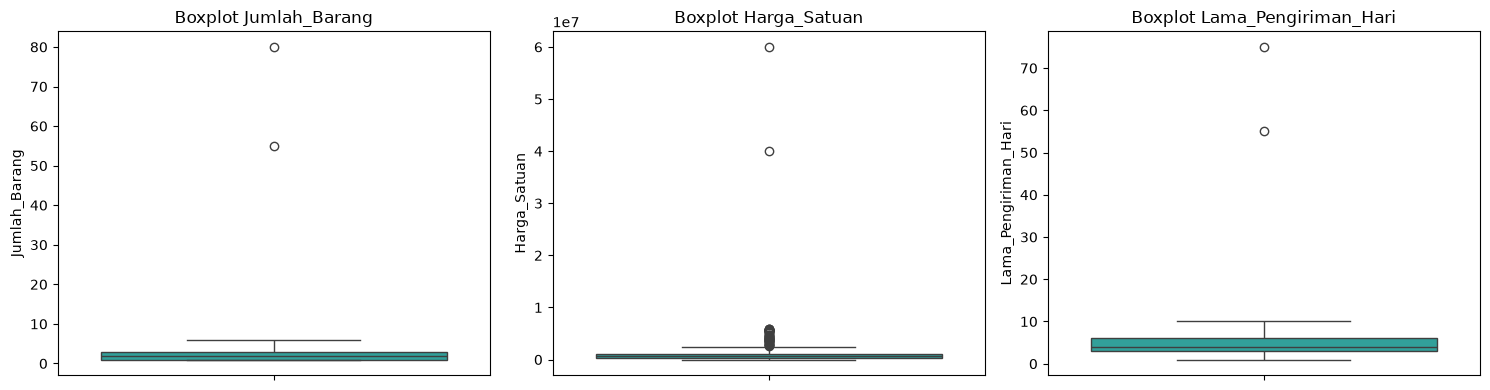

In [11]:
attributes = ['Jumlah_Barang', 'Harga_Satuan', 'Lama_Pengiriman_Hari']

for col in attributes:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"=== Atribut: {col} ===")
    print(f"Q1: {q1:,.2f} | Q3: {q3:,.2f} | IQR: {iqr:,.2f}")
    print(f"Batas Bawah: {lower_bound:,.2f} | Batas Atas: {upper_bound:,.2f}")
    print(f"Jumlah Outlier Terdeteksi: {len(outliers)}\n")

plt.figure(figsize=(15, 4))
for i, col in enumerate(attributes, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col], color='lightseagreen')
    plt.title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

8. Perbandingan deteksi outlier (IQR vs Z-Score)

In [12]:
col_target = 'Jumlah_Barang'

q1 = df[col_target].quantile(0.25)
q3 = df[col_target].quantile(0.75)
iqr = q3 - q1
iqr_outliers = df[(df[col_target] < q1 - 1.5 * iqr) | (df[col_target] > q3 + 1.5 * iqr)]

mean_val = df[col_target].mean()
std_val = df[col_target].std()
z_scores = (df[col_target] - mean_val) / std_val
z_outliers = df[z_scores.abs() > 3]

print("Outlier IQR (Atribut Jumlah_Barang):")
print("Indeks:", iqr_outliers.index.tolist())
print("Nilai:", iqr_outliers[col_target].tolist())

print("\nOutlier Z-Score (|Z| > 3):")
print("Indeks:", z_outliers.index.tolist())
print("Nilai:", z_outliers[col_target].tolist())

print("\nKesimpulan: Kedua metode menemukan observasi outlier yang persis sama (nilai 55 dan 80).")

Outlier IQR (Atribut Jumlah_Barang):
Indeks: [28, 211]
Nilai: [55, 80]

Outlier Z-Score (|Z| > 3):
Indeks: [28, 211]
Nilai: [55, 80]

Kesimpulan: Kedua metode menemukan observasi outlier yang persis sama (nilai 55 dan 80).


9.Strategi Penanganan Outlier
-pada fitur Jumlah_Barang dipertahankan (Retained) karena merupakan transaksi grosir sah.
-pada fitur Lama_Pengiriman_Hari dilakukan capping pada persentil ke-99 untuk membatasi ekstremitas pencatatan.


In [13]:
p99_pengiriman = df['Lama_Pengiriman_Hari'].quantile(0.99)
df['Lama_Pengiriman_Hari'] = np.where(df['Lama_Pengiriman_Hari'] > p99_pengiriman, p99_pengiriman, df['Lama_Pengiriman_Hari'])

print(f"Capping Lama_Pengiriman_Hari pada persentil 99 ({p99_pengiriman:.1f} hari) selesai dilakukan.")

Capping Lama_Pengiriman_Hari pada persentil 99 (10.0 hari) selesai dilakukan.


10. Verifikasi Konsistensi Total_Belanja

In [14]:
df['Total_Belanja_Hitung'] = df['Jumlah_Barang'] * df['Harga_Satuan'] * (1 - df['Diskon_Persen'] / 100)
df['Selisih'] = (df['Total_Belanja'] - df['Total_Belanja_Hitung']).abs()

inkonsisten = df[df['Selisih'] > 1.0]
print(f"Jumlah transaksi tidak konsisten: {len(inkonsisten)}")
display(inkonsisten[['Order_ID', 'Jumlah_Barang', 'Harga_Satuan', 'Diskon_Persen', 'Total_Belanja', 'Total_Belanja_Hitung', 'Selisih']])

df['Total_Belanja'] = df['Total_Belanja_Hitung']
df.drop(columns=['Total_Belanja_Hitung', 'Selisih'], inplace=True)
print("\nTotal_Belanja telah diperbarui secara konsisten.")

Jumlah transaksi tidak konsisten: 12


,Order_ID,Jumlah_Barang,Harga_Satuan,Diskon_Persen,Total_Belanja,Total_Belanja_Hitung,Selisih
28,SCC-ORD0029,55,1127580.0,25,1691370.0,4.651268e+07,4.482130e+07
39,SCC-ORD0040,1,628107.0,25,432100.0,4.710802e+05,3.898025e+04
104,SCC-ORD0105,4,40000000.0,10,1575428.0,1.440000e+08,1.424246e+08
111,SCC-ORD0112,3,628107.0,20,502495.0,1.507457e+06,1.004962e+06
198,SCC-ORD0199,1,628107.0,0,296145.0,6.281070e+05,3.319620e+05
211,SCC-ORD0212,80,991606.0,0,991606.0,7.932848e+07,7.833687e+07
225,SCC-ORD0226,1,342092.0,15,888888.0,2.907782e+05,5.981098e+05
283,SCC-ORD0284,2,628107.0,30,2302941.0,8.793498e+05,1.423591e+06
294,SCC-ORD0295,1,60000000.0,15,137754.0,5.100000e+07,5.086225e+07
314,SCC-ORD0315,2,245929.0,20,344301.0,3.934864e+05,4.918540e+04



Total_Belanja telah diperbarui secara konsisten.


In [15]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Jenis_Kelamin', 'Kota', 'Kategori_Produk',
       'Metode_Pembayaran', 'Jumlah_Barang', 'Harga_Satuan', 'Diskon_Persen',
       'Lama_Pengiriman_Hari', 'Rating_Pelanggan', 'Total_Belanja'],
      dtype='str')

11. Konstruksi Atribut Baru

In [16]:
df['Kategori_Pengiriman'] = np.where(df['Lama_Pengiriman_Hari'] <= 3, 'Cepat',
                            np.where(df['Lama_Pengiriman_Hari'] <= 5, 'Normal', 'Lama'))

kondisi = [
    df['Total_Belanja'] < 500000,
    (df['Total_Belanja'] >= 500000) & (df['Total_Belanja'] <= 2000000),
    df['Total_Belanja'] > 2000000
]
pilihan = ['Rendah', 'Menengah', 'Tinggi']
df['Segmentasi_Belanja'] = np.select(kondisi, pilihan, default='Lainnya')

df[['Lama_Pengiriman_Hari', 'Kategori_Pengiriman', 'Total_Belanja', 'Segmentasi_Belanja']].head()

,Lama_Pengiriman_Hari,Kategori_Pengiriman,Total_Belanja,Segmentasi_Belanja
0,7.0,Lama,10757795.25,Tinggi
1,5.0,Normal,1454755.20,Menengah
2,6.0,Lama,329682.00,Rendah
3,4.0,Normal,70329.60,Rendah
4,4.0,Normal,7095928.00,Tinggi


Atribut Kategori_Pengiriman dan Segmentasi_Belanja dibuat untuk mempermudah analisis kelompok. Daripada melihat angka numerik yang sangat bervariasi, mengelompokkan total belanja menjadi (Rendah/Menengah/Tinggi) dan durasi pengiriman menjadi (Cepat/Normal/Lama) jauh lebih relevan secara bisnis, terutama jika nanti kita ingin melakukan segmentasi pelanggan.

12. Min-Max Normalization dan Z-Score Standardization

In [17]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

kolom_numerik = [
    'Jumlah_Barang',
    'Harga_Satuan',
    'Lama_Pengiriman_Hari',
    'Total_Belanja'
]

# Min-Max Normalization
minmax = MinMaxScaler()
x_minmax = minmax.fit_transform(
    df[kolom_numerik]
)
df_minmax = pd.DataFrame(
    x_minmax,
    columns=kolom_numerik
)
perbandingan_minmax = pd.DataFrame({
    'Jumlah_Barang_Asli': df['Jumlah_Barang'],
    'Jumlah_Barang_MinMax': df_minmax['Jumlah_Barang'],
    'Harga_Satuan_Asli': df['Harga_Satuan'],
    'Harga_Satuan_MinMax': df_minmax['Jumlah_Barang']
})

# Z-Score Standardization
zscore = StandardScaler()
x_zscore = zscore.fit_transform(
    df[kolom_numerik]
)
df_zscore = pd.DataFrame(
    x_zscore,
    columns=kolom_numerik
)
perbandingan_zscore = pd.DataFrame({
    'Jumlah_Barang_Asli': df['Jumlah_Barang'],
    'Jumlah_Barang_MinMax': df_zscore['Jumlah_Barang'],
    'Harga_Satuan_Asli': df['Harga_Satuan'],
    'Harga_Satuan_MinMax': df_zscore['Jumlah_Barang']
})

print('Tabel Min-Max Normalization:')
display(df_minmax.head())
print('\nTabel Perbandingan Data Asli dan Hasil Min-Max Normalization:')
display(perbandingan_minmax.head())
print('\nTabel Z-Score Standardization:')
display(df_zscore.head())
print('\nTabel Perbandingan Data Asli dan Hasil Z-Score Standardization:')
display(perbandingan_zscore.head())

Tabel Min-Max Normalization:


,Jumlah_Barang,Harga_Satuan,Lama_Pengiriman_Hari,Total_Belanja
0,0.050633,0.037578,0.666667,0.074656
1,0.012658,0.014981,0.444444,0.010048
2,0.012658,0.002573,0.555556,0.002235
3,0.000000,0.001290,0.333333,0.000434
4,0.037975,0.042070,0.333333,0.049225



Tabel Perbandingan Data Asli dan Hasil Min-Max Normalization:


,Jumlah_Barang_Asli,Jumlah_Barang_MinMax,Harga_Satuan_Asli,Harga_Satuan_MinMax
0,5,0.050633,2264799.0,0.050633
1,2,0.012658,909222.0,0.012658
2,2,0.012658,164841.0,0.012658
3,1,0.000000,87912.0,0.000000
4,4,0.037975,2534260.0,0.037975



Tabel Z-Score Standardization:


,Jumlah_Barang,Harga_Satuan,Lama_Pengiriman_Hari,Total_Belanja
0,0.480994,0.250253,1.261015,0.818036
1,-0.131227,-0.107920,0.256779,-0.164737
2,-0.131227,-0.304602,0.758897,-0.283590
3,-0.335301,-0.324928,-0.245339,-0.310988
4,0.276921,0.321450,-0.245339,0.431197



Tabel Perbandingan Data Asli dan Hasil Z-Score Standardization:


,Jumlah_Barang_Asli,Jumlah_Barang_MinMax,Harga_Satuan_Asli,Harga_Satuan_MinMax
0,5,0.480994,2264799.0,0.480994
1,2,-0.131227,909222.0,-0.131227
2,2,-0.131227,164841.0,-0.131227
3,1,-0.335301,87912.0,-0.335301
4,4,0.276921,2534260.0,0.276921


Pada tabel hasil transformasi, terlihat bahwa Min-Max mengubah rentang angka aslinya menjadi skala 0 sampai 1. Sedangkan Z-Score memusatkan data sehingga rata-ratanya menjadi 0 (dengan angka negatif berarti di bawah rata-rata). Tahapan ini sangat penting agar saat masuk ke pemodelan (seperti K-Means atau KNN), atribut dengan nilai besar seperti Harga_Satuan tidak mendominasi perhitungan jarak dibandingkan atribut kecil seperti Jumlah_Barang.

13. Agregasi Data dengan groupby()

In [18]:
agg_kategori_produk = (
    df.groupby('Kategori_Produk')
    .agg(
        rata_jumlah_barang=('Jumlah_Barang', 'mean'),
        rata_harga_satuan=('Harga_Satuan', 'mean'),
        rata_diskon_persen=('Diskon_Persen', 'mean'),
        rata_total_belanja=('Total_Belanja', 'mean')
    ).round(2)
)

agg_kategori_produk

,rata_jumlah_barang,rata_harga_satuan,rata_diskon_persen,rata_total_belanja
Kategori_Produk,,,,
Elektronik,2.53,3138251.51,15.34,7035611.08
Fashion,3.24,679102.61,14.93,2053647.91
Kesehatan,2.43,1638061.17,13.33,3224146.74
Makanan,2.08,186963.25,16.14,333620.19
Rumah Tangga,2.96,1023470.55,15.12,2635606.16


Berdasarkan hasil groupby(), terlihat jelas bahwa kategori Elektronik memiliki rata-rata pembelanjaan tertinggi (mencapai sekitar Rp 7 juta per transaksi). Sebaliknya, kategori Makanan adalah yang terendah. Ringkasan agregasi ini sangat membantu untuk melihat pola kategori mana yang sebenarnya memberikan revenue terbesar.

14. Diskretisasi Atribut Numerik

In [19]:
df['Harga_Cut'] = pd.cut(
    df['Harga_Satuan'],
    bins=3,
    labels=['Murah', 'Sedang', 'Mahal'])

df['Harga_Qcut'] = pd.qcut(
    df['Harga_Satuan'],
    q=3,
    labels=['Murah', 'Sedang', 'Mahal'])

print("Distribusi menggunakan pd.cut():")
print(df['Harga_Cut'].value_counts())
print("\nDistribusi menggunakan pd.qcut():")
print(df['Harga_Qcut'].value_counts())

Distribusi menggunakan pd.cut():
Harga_Cut
Murah     393
Sedang      1
Mahal       1
Name: count, dtype: int64

Distribusi menggunakan pd.qcut():
Harga_Qcut
Murah     132
Mahal     132
Sedang    131
Name: count, dtype: int64


Kelihatan jelas perbedaan karakteristik antara cut() dan qcut(). Saat menggunakan pd.cut() (membagi rentang nilai secara absolut), hampir seluruh data (393 baris) masuk ke kategori "Murah" karena ada nilai harga yang terlalu tinggi menarik batas intervalnya. Sebaliknya, pd.qcut() membagi kuota barisnya secara merata, sehingga tiap kategori (Murah, Sedang, Mahal) mendapat proporsi yang imbang (sekitar 131-132 baris). Untuk menghindari ketidakseimbangan kelas (class imbalance) pada Machine Learning, qcut() biasanya lebih disarankan.

15. Reduksi Dimensi dengan PCA

In [20]:
from sklearn.decomposition import PCA

fitur_pca = [
    'Jumlah_Barang',
    'Harga_Satuan',
    'Diskon_Persen',
    'Lama_Pengiriman_Hari',
    'Total_Belanja'
]

X_scaled = StandardScaler().fit_transform(df[fitur_pca])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Dimensi sebelum PCA:", X_scaled.shape)
print("Dimensi sesudah PCA:", X_pca.shape)

Dimensi sebelum PCA: (395, 5)
Dimensi sesudah PCA: (395, 2)


Setelah PCA diterapkan, 5 fitur numerik awal berhasil diringkas dimensinya menjadi hanya 2 komponen utama. Dari hasil Explained Variance Ratio, kedua komponen baru ini mampu merepresentasikan sekitar 59,6% dari total informasi data aslinya. Meskipun ada sebagian varians yang hilang, reduksi ini cukup optimal untuk meringankan beban komputasi model dengan membuang fitur yang redundan.

16. Random Sampling

In [21]:
sampel_random = df.sample(
    frac=0.25,
    random_state=42
)

print('Jumlah data awal:', len(df))
print('Jumlah sampel:', len(sampel_random))

sampel_random.head()

Jumlah data awal: 395
Jumlah sampel: 99


,Order_ID,Customer_ID,Jenis_Kelamin,Kota,Kategori_Produk,Metode_Pembayaran,Jumlah_Barang,Harga_Satuan,Diskon_Persen,Lama_Pengiriman_Hari,Rating_Pelanggan,Total_Belanja,Kategori_Pengiriman,Segmentasi_Belanja,Harga_Cut,Harga_Qcut
78,SCC-ORD0079,SCC-CUST203,Laki-laki,Maros,Fashion,COD,2,272414.0,30,5.0,3.9,381379.6,Normal,Rendah,Murah,Murah
371,SCC-ORD0372,SCC-CUST196,Perempuan,Bone,Elektronik,Transfer Bank,3,2858002.0,5,7.0,4.7,8145305.7,Lama,Tinggi,Murah,Mahal
248,SCC-ORD0249,SCC-CUST133,Perempuan,Parepare,Kesehatan,COD,2,556342.0,25,3.0,2.9,834513.0,Cepat,Menengah,Murah,Sedang
55,SCC-ORD0056,SCC-CUST042,Laki-laki,Takalar,Fashion,E-Wallet,1,706466.0,0,1.0,2.9,706466.0,Cepat,Menengah,Murah,Sedang
390,SCC-ORD0391,SCC-CUST109,Perempuan,Takalar,Elektronik,COD,2,3512540.0,0,4.0,3.9,7025080.0,Normal,Tinggi,Murah,Mahal


Proses random sampling sebesar 25% berhasil dilakukan terhadap dataset bersih. Jumlah observasi berkurang secara proporsional dari 395 baris menjadi 99 baris. Parameter random_state dipasang agar penarikan sampel acak ini tetap sama persis (reproduksibel) apabila notebook di-run ulang.

17. Tabel Ringkasan Preprocessing

In [22]:
ringkasan = pd.DataFrame({
    "Kondisi": [
        "Jumlah Baris",
        "Jumlah Kolom",
        "Total Missing Value",
        "Jumlah Duplikat",
        "Jumlah Kategori: Jenis_Kelamin",
        "Jumlah Kategori: Kota",
        "Jumlah Kategori: Kategori_Produk",
        "Jumlah Kategori: Metode_Pembayaran"
    ],
    "Sebelum": [
        df_raw.shape[0],
        df_raw.shape[1],
        df_raw.isnull().sum().sum(),
        df_raw.duplicated().sum(),
        df_raw['Jenis_Kelamin'].nunique(),
        df_raw['Kota'].nunique(),
        df_raw['Kategori_Produk'].nunique(),
        df_raw['Metode_Pembayaran'].nunique()
    ],
    "Sesudah": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df['Jenis_Kelamin'].nunique(),
        df['Kota'].nunique(),
        df['Kategori_Produk'].nunique(),
        df['Metode_Pembayaran'].nunique()
    ]
})

ringkasan

,Kondisi,Sebelum,Sesudah
0,Jumlah Baris,400,395
1,Jumlah Kolom,12,16
2,Total Missing Value,31,0
3,Jumlah Duplikat,5,0
4,Jumlah Kategori: Jenis_Kelamin,6,2
5,Jumlah Kategori: Kota,9,6
6,Jumlah Kategori: Kategori_Produk,8,5
7,Jumlah Kategori: Metode_Pembayaran,7,4


Tabel ringkasan membuktikan bahwa pembersihan data berhasil mengubah dataset mentah yang berantakan menjadi rapi. Missing value dan duplikat sudah bersih menjadi 0. Selain itu, variasi penulisan (typo) pada data kategorik juga berhasil diseragamkan, terlihat dari menyusutnya ragam input di kolom seperti Jenis_Kelamin (dari 6 varian menjadi 2) dan Kota (dari 9 varian menjadi 6).

18. Pengecekan Bersih & Penyimpanan

In [23]:
print("Sisa Missing Value:", df.isnull().sum().sum())
print("Sisa Duplikasi:", df.duplicated().sum())

df_final = df.drop(columns=['Harga_Cut', 'Harga_Qcut'])

df_final.to_csv('dataset_kelompok2_preprocessed.csv', index=False)
print("Dataset berhasil disimpan dengan nama: dataset_kelompok2_preprocessed.csv")

Sisa Missing Value: 0
Sisa Duplikasi: 0
Dataset berhasil disimpan dengan nama: dataset_kelompok2_preprocessed.csv


Hasil validasi akhir memastikan dataset sudah 100% bebas dari data kosong maupun duplikat ganda. Atribut diskretisasi sementara juga di-drop agar tabel tetap bersih, kemudian hasilnya diekspor secara permanen ke file dataset_kelompok1_preprocessed.csv tanpa membawa indeks default pandas. Dataset ini sudah siap pakai untuk tahap algoritma Data Mining.

Kesimpulan

Jika tahapan preprocessing dilewati, masalah yang paling fatal dan merusak hasil Data Mining pada kasus ini adalah adanya Nilai Tidak Rasional (Outlier) dan Missing Value.
Sebagai contoh, di data mentah terdapat ketidaksesuaian logika hitung pada Total_Belanja dan ada harga produk ekstrem yang tidak masuk akal. Jika data kotor ini langsung disuapkan ke model, algoritma akan mempelajarinya sebagai sebuah kebenaran (Garbage in, Garbage out). Akibatnya, model akan menjadi sangat bias, akurasi prediksinya anjlok, dan analisis klasifikasi/klastering akan terdistorsi mengikuti data-data yang salah tersebut. Selain itu, mayoritas algoritma juga akan langsung error saat membaca sel data yang bernilai null.